# Chapitre 1 - Cours 5 : données, droit et société

Le dernier compromis du chapitre ne se joue pas entre deux technologies, mais entre les
besoins d'une entreprise et les droits des personnes dont elle traite les données. Le
livre insiste : les contraintes légales influencent désormais les **fondations** de la
conception des systèmes de données. Ce notebook couvre la section *Data Systems, Law, and
Society* et montre, par des expériences, pourquoi des exigences juridiques simples à
énoncer sont difficiles à implémenter.

**Plan.**

1. Une responsabilité qui dépasse l'entreprise : RGPD, décisions automatisées, et ce
   que cela implique techniquement.
2. Le droit à l'effacement face aux journaux immuables : compaction ou effacement
   cryptographique.
3. Effacer aussi les données dérivées : combien de temps une donnée survit-elle ?
4. La minimisation des données : coûts cachés du stockage, réidentification,
   pseudonymisation.
5. Résidence des données et normes du secteur.

In [1]:
import hashlib

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from ddia import architecture as ar
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Une responsabilité qui dépasse l'entreprise (section *Data Systems, Law, and Society*)

Servir les besoins de son entreprise ne suffit plus : les ingénieurs de données ont aussi
une responsabilité envers la société. Deux constats du livre :

- **la loi** : depuis 2018, le RGPD (règlement général sur la protection des données,
  GDPR en anglais) donne aux résidents de nombreux pays européens davantage de contrôle et
  de droits sur leurs données personnelles ; des réglementations proches existent ailleurs
  (le CCPA en Californie), et les règles sur l'IA (le règlement européen sur l'IA)
  encadrent encore davantage l'usage des données personnelles ;
- **les effets sur les personnes**, même hors réglementation : les réseaux sociaux
  changent la manière de s'informer, donc les opinions et peut-être les élections ; des
  systèmes automatisés décident qui obtient un prêt, une assurance, un entretien
  d'embauche, ou qui est suspecté d'un délit.

Personne n'a besoin de devenir juriste, mais une culture de base en droit et en éthique
est aussi importante, selon le livre, qu'une culture de base en systèmes distribués. Le
schéma ci-dessous relie quelques principes juridiques aux mécanismes techniques qu'ils
exigent, et que les chapitres suivants permettent de construire.

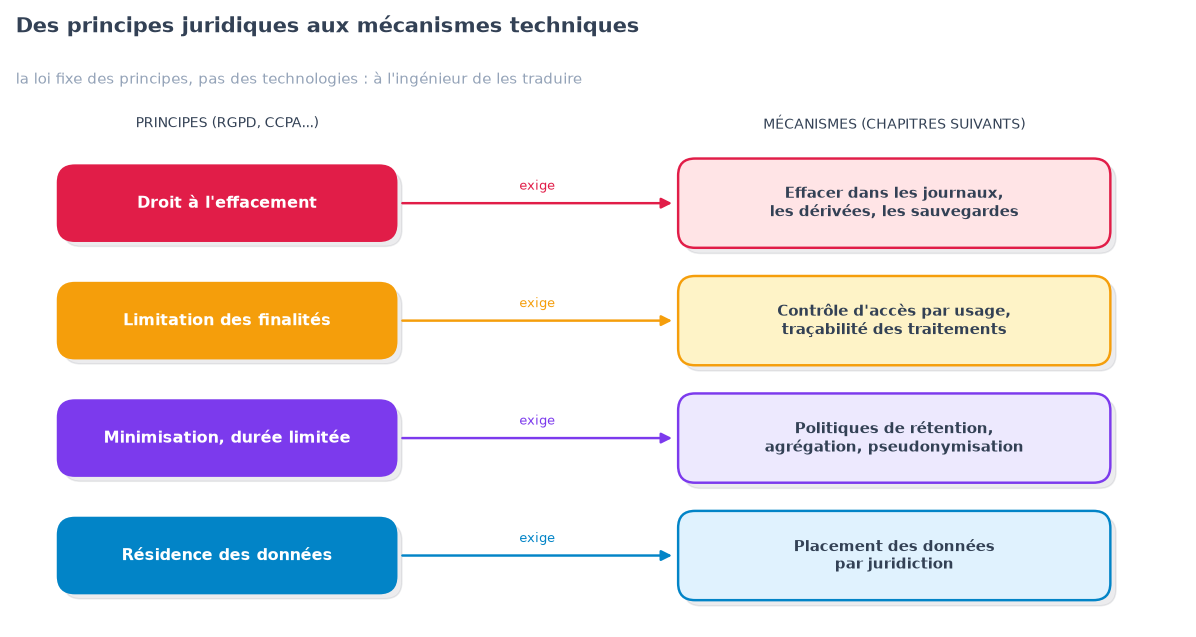

In [2]:
d = Diagram(12.5, 5.6, title="Des principes juridiques aux mécanismes techniques",
            subtitle="la loi fixe des principes, pas des technologies : à l'ingénieur de les traduire")
law = [("eff", "Droit à l'effacement", ROSE), ("fin", "Limitation des finalités", AMBER),
       ("min", "Minimisation, durée limitée", VIOLET), ("res", "Résidence des données", SKY)]
tech = [("t_eff", "Effacer dans les journaux,\nles dérivées, les sauvegardes"), ("t_fin", "Contrôle d'accès par usage,\ntraçabilité des traitements"),
        ("t_min", "Politiques de rétention,\nagrégation, pseudonymisation"), ("t_res", "Placement des données\npar juridiction")]
for i, ((k, t, c), (k2, t2)) in enumerate(zip(law, tech)):
    y = 4.5 - i * 1.25
    d.box(k, 2.3, y, t, color=c, w=3.6, h=0.8, filled=True)
    d.box(k2, 9.4, y, t2, color=c, w=4.6, h=0.95, fontsize=9.5)
    d.arrow(k, k2, "exige", color=c)
d.note(2.3, 5.35, "PRINCIPES (RGPD, CCPA...)", color=SLATE, style="normal")
d.note(9.4, 5.35, "MÉCANISMES (CHAPITRES SUIVANTS)", color=SLATE, style="normal")
d.show()

Le livre souligne qu'il n'existe pas aujourd'hui de liste claire des technologies ou
architectures « conformes au RGPD » : le règlement énonce volontairement des principes
généraux, sujets à interprétation, pour ne pas dépendre d'une technologie vite dépassée.
La conformité n'a donc pas de réponse simple ; regardons les cas les plus techniques.

> **À retenir.** Les systèmes de données sont soumis au droit (RGPD, CCPA, règles sur l'IA)
> et ont des effets sociaux réels. La loi fixe des principes ; les traduire en mécanismes
> techniques est un travail d'ingénierie, souvent difficile.

## 2. Le droit à l'effacement face aux journaux immuables (section *Data Systems, Law, and Society*)

Le RGPD donne à chacun le droit de faire effacer ses données sur demande (le « droit à
l'oubli »). Or beaucoup de systèmes de données reposent sur des structures **immuables**,
comme les **journaux en ajout seul** (« append-only logs ») : moteurs de stockage
(chapitre 4), réplication (chapitre 6), flux d'événements
(chapitre 12). Comment supprimer une donnée au milieu d'un fichier censé ne
jamais changer ?

Deux stratégies :

- la **compaction** : réécrire le journal sans les entrées de la personne
  (`ar.compact_without`). Correct, mais coûteux : chaque effacement réécrit tout ce qui
  reste ;
- l'**effacement cryptographique** (« crypto-shredding ») : chiffrer dès l'écriture les
  données de chaque personne avec **sa propre clé**, conservée à part ; effacer la
  personne revient à **détruire sa clé** (`ar.ShreddableLog`). Le journal reste
  intact, mais ses entrées deviennent illisibles.

Commençons par vérifier le principe sur un petit journal (le chiffrement par flot
utilisé ici, fondé sur SHA-256, est pédagogique et ne doit pas servir en production).

In [3]:
log = ar.ShreddableLog(seed=1)
events = [("alice", "connexion depuis 82.64.x.x"), ("bob", "achat : livre"), ("alice", "recherche : clinique"),
          ("carol", "achat : vélo"), ("alice", "position : 48.85, 2.35"), ("bob", "connexion")]
for u, e in events:
    log.append(u, e)
before = log.read()
size = log.size_bytes
rewritten = log.forget("alice")
after = log.read()
print(f"taille du journal : {size} octets avant, {log.size_bytes} octets après ; octets réécrits : {rewritten}")
pd.DataFrame({"utilisateur": [u for u, _ in log.entries],
              "octets stockés (extrait)": [blob[:8].hex() + "..." for _, blob in log.entries],
              "lisible avant": [t for _, t in before],
              "lisible après oubli d'alice": [t if u in log.keys else "(clé détruite)" for u, t in before]})

taille du journal : 103 octets avant, 103 octets après ; octets réécrits : 0


,utilisateur,octets stockés (extrait),lisible avant,lisible après oubli d'alice
0,alice,11068615533179bc...,connexion depuis 82.64.x.x,(clé détruite)
1,bob,9184d69cedc654ee...,achat : livre,achat : livre
2,alice,000c8b13533b73bb...,recherche : clinique,(clé détruite)
3,carol,076f729a24427c5f...,achat : vélo,achat : vélo
4,alice,02069b1242207fbd...,"position : 48.85, 2.35",(clé détruite)
5,bob,9388d093fc9e07a1...,connexion,connexion


Les octets chiffrés d'Alice sont toujours dans le journal (pas un octet n'a été réécrit,
la taille est inchangée), mais sans sa clé, plus personne ne peut les lire, y compris dans
les copies répliquées ou sauvegardées du journal, pourvu que la clé, elle, n'ait été
copiée nulle part. Comparons maintenant les **coûts** sur un journal réaliste : 10 millions
d'entrées de 200 octets (2 Go), et des demandes d'effacement qui arrivent au fil de l'eau.

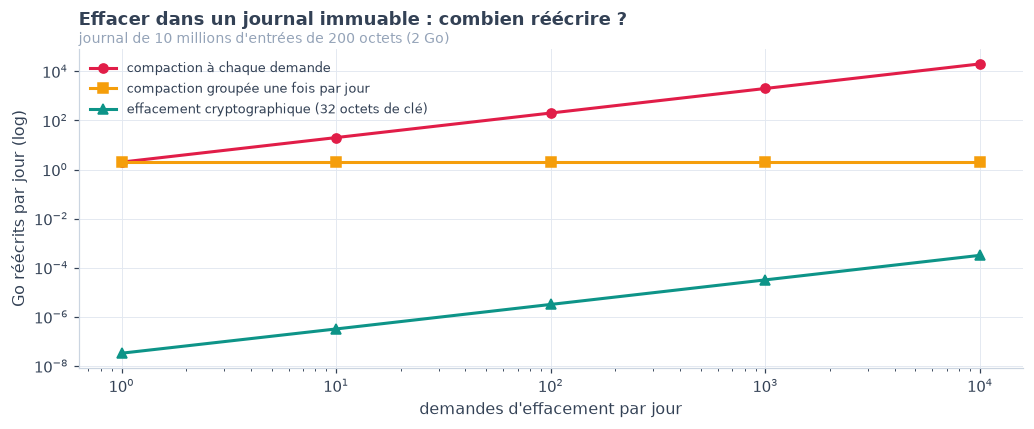

In [4]:
LOG_BYTES = 10_000_000 * 200
req_per_day = np.array([1, 10, 100, 1000, 10_000])
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.loglog(req_per_day, req_per_day * LOG_BYTES / 1e9, "o-", color=ROSE, label="compaction à chaque demande")
ax.loglog(req_per_day, np.full(req_per_day.size, LOG_BYTES / 1e9), "s-", color=AMBER,
          label="compaction groupée une fois par jour")
ax.loglog(req_per_day, req_per_day * 32 / 1e9 + 1e-9, "^-", color=TEAL, label="effacement cryptographique (32 octets de clé)")
ax.set_xlabel("demandes d'effacement par jour"); ax.set_ylabel("Go réécrits par jour (log)")
ax.set_title("Effacer dans un journal immuable : combien réécrire ?")
subtitle(ax, "journal de 10 millions d'entrées de 200 octets (2 Go)")
ax.legend(fontsize=8.5); plt.tight_layout(); plt.show()

Compacter à chaque demande devient vite intenable (10 000 demandes par jour, 20 To
réécrits) ; grouper les compactions borne le coût à une réécriture par jour, au prix d'un
**délai** pendant lequel la donnée existe encore ; l'effacement cryptographique ne
supprime que quelques octets de clé. Il a toutefois ses propres exigences : gérer des
millions de clés de façon fiable (perdre la base de clés, c'est perdre toutes les
données), ne jamais les copier dans les sauvegardes ordinaires, et convaincre qu'un texte
chiffré dont la clé est détruite vaut effacement, ce qui reste une question
d'interprétation juridique.

> **À retenir.** Le droit à l'effacement heurte les structures immuables. La compaction
> réécrit le journal (coûteux, ou différé si on la groupe) ; l'effacement cryptographique
> détruit une clé par personne (immédiat, mais exige une gestion des clés irréprochable).